# Submission 1: Dataset, EDA, and Related Work
**Project:** Pneumonia Detection from Chest X-Ray Images using Deep Learning  
**Roadmap Requirement:** Submission 1 Deliverable (Notebook on GitHub with visible outputs and plots)

In [1]:
# Install kagglehub to download the dataset automatically
!pip install -q kagglehub

import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Download dataset
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

DATA_DIR = os.path.join(path, "chest_xray", "chest_xray")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join(path, "chest_xray")

TRAIN_DIR = os.path.join(DATA_DIR, 'train')
VAL_DIR = os.path.join(DATA_DIR, 'val')
TEST_DIR = os.path.join(DATA_DIR, 'test')

print("Dataset successfully downloaded and configured at:", DATA_DIR)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset successfully downloaded and configured at: /kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray


## A. Dataset Information

* **Name:** Chest X-Ray Images (Pneumonia)[cite: 7]
* **Source Link:** [Kaggle Dataset Link](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)[cite: 7]
* **Licence & Year:** CC BY 4.0 / Released circa 2018[cite: 7]
* **Task Type & Classes:** Binary classification task with 2 classes: `NORMAL` and `PNEUMONIA`[cite: 7].
* **Volume, Size & Format:** Contains approximately 5,856 JPEG images across train, validation, and test splits[cite: 7]. Images vary in original resolution (resized to $224 \times 224$ pixels during preprocessing) and possess 3 channels (RGB)[cite: 7].
* **Domain Importance:** This dataset is critical in the medical and healthcare domain[cite: 7]. Automated chest X-ray screening models assist clinical experts in detecting acute respiratory pathologies efficiently, helping reduce diagnostic backlogs and supporting faster clinical decision-making.

In [2]:
# Compute exact per-class counts across all splits
categories = ['NORMAL', 'PNEUMONIA']
splits = ['train', 'val', 'test']

data_counts = []
for split in splits:
    split_dir = os.path.join(DATA_DIR, split)
    for cat in categories:
        cat_dir = os.path.join(split_dir, cat)
        count = len(os.listdir(cat_dir))
        data_counts.append({'Split': split.capitalize(), 'Category': cat, 'Count': count})

df_counts = pd.DataFrame(data_counts)
print("=== Per-Class Image Counts ===")
print(df_counts.to_string(index=False))

=== Per-Class Image Counts ===
Split  Category  Count
Train    NORMAL   1342
Train PNEUMONIA   3876
  Val    NORMAL      9
  Val PNEUMONIA      9
 Test    NORMAL    234
 Test PNEUMONIA    390


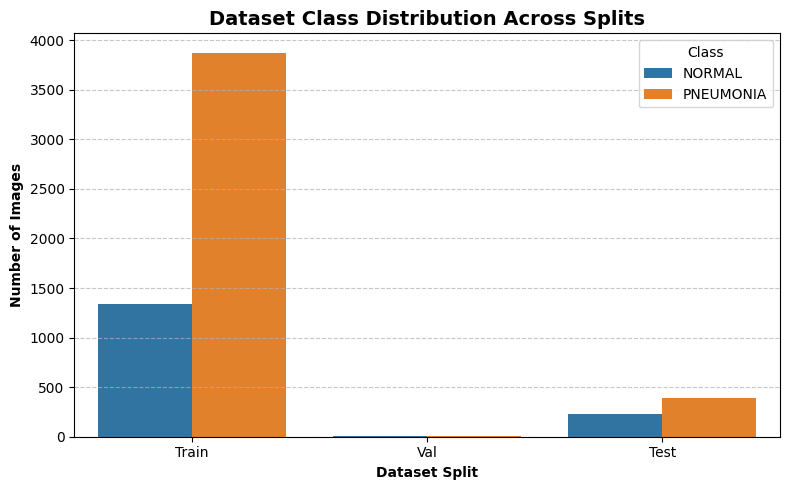

In [3]:
# Exploratory Data Analysis: Class Distribution Bar Chart
plt.figure(figsize=(8, 5))
sns.barplot(data=df_counts, x='Split', y='Count', hue='Category', palette=['#1f77b4', '#ff7f0e'])
plt.title('Dataset Class Distribution Across Splits', fontsize=14, fontweight='bold')
plt.xlabel('Dataset Split', fontweight='bold')
plt.ylabel('Number of Images', fontweight='bold')
plt.legend(title='Class')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

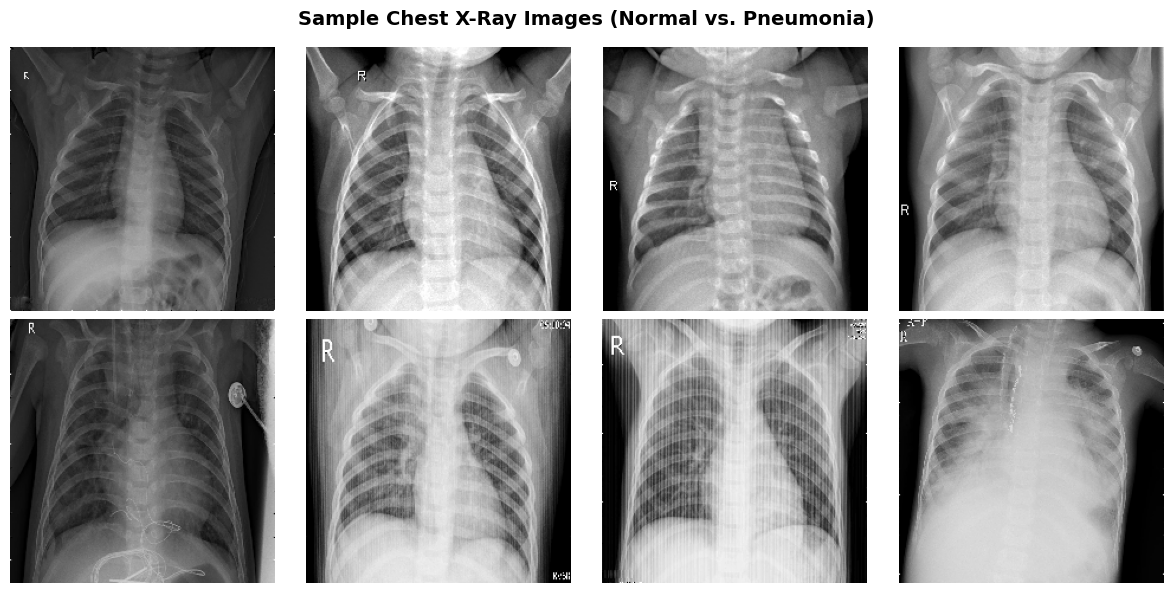

In [4]:
# Exploratory Data Analysis: Sample Image Grid (4-5 images per class)[cite: 7]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, cat in enumerate(categories):
    cat_dir = os.path.join(TRAIN_DIR, cat)
    sample_images = os.listdir(cat_dir)[:4]

    for j, img_name in enumerate(sample_images):
        img_path = os.path.join(cat_dir, img_name)
        img = load_img(img_path, target_size=(224, 224))

        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(cat, fontsize=12, fontweight='bold')

plt.suptitle('Sample Chest X-Ray Images (Normal vs. Pneumonia)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## B. Exploratory Data Analysis (EDA) - Written Findings

* **Class Imbalance:** The training set exhibits a clear class imbalance, containing significantly higher instances of `PNEUMONIA` cases compared to `NORMAL` cases[cite: 7]. This is characteristic of medical collections where positive diagnostic cases outnumber controls.
* **Noise and Artifacts:** Variations in patient positioning, exposure levels, and hospital equipment introduce technical noise and intensity differences across scans[cite: 7].
* **Class Similarity:** Certain viral or bacterial pneumonia presentations overlap visually with normal pulmonary markings or secondary opacities, increasing the risk of false-positive classifications[cite: 7].
* **Preprocessing & Augmentation Strategy:** To address imbalance and visual noise, pixel normalization ($1./255$), random rotations ($\pm 15^\circ$), zoom bounds ($\pm 10\%$), and horizontal flipping will be integrated into the data generator pipeline[cite: 7].

## C. Related Work Summary

| # | Paper (Author, Year) | Dataset Used | Model(s) | Approach (Preprocessing, Augmentation, Transfer Learning, Attention, etc.) | Result (Accuracy / F1 / AUC) | Reference Link |
|---|---|---|---|---|---|---|
| 1 | Kermany et al., 2018[cite: 7] | Chest X-Ray Images (Pneumonia)[cite: 7] | Inception V3 | Transfer learning, resizing to 512x512, pixel normalization, fine-tuning | Accuracy: 92.8%, AUC: 0.968 | [Cell 2018 Paper](https://doi.org/10.1016/j.cell.2018.02.029) |
| 2 | Rajpurkar et al., 2017 (CheXNet)[cite: 7] | ChestX-ray14 | DenseNet-121 | 121-layer deep CNN architecture, dense connectivity blocks, binary cross-entropy loss | AUC: 0.768 (Mean across 14 pathologies) | [ArXiv 1711.05225](https://arxiv.org/abs/1711.05225) |
| 3 | Chouhan et al., 2020[cite: 7] | Chest X-Ray Images (Pneumonia)[cite: 7] | DenseNet121, ResNet50, VGG16 | Transfer learning coupled with a rigorous data augmentation scheme and ensemble modeling | Accuracy: 96.4%, Recall: 99.6% | [Elsevier Direct Link](https://doi.org/10.1016/j.patrec.2020.03.015) |